# Análise Exploratória de Dados — Veículos Usados

## Introdução

Este projeto tem como objetivo analisar dados de anúncios de veículos usados, identificando padrões e tendências relacionados aos preços, quilometragem e características dos veículos.

A análise será realizada utilizando Python, Pandas e ferramentas de visualização de dados.


In [22]:
%pip install pandas


Defaulting to user installation because normal site-packages is not writeable

[notice] A new release of pip available: 22.2.2 -> 26.3
[notice] To update, run: python3.10 -m pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


python3.10 -m pip install --upgrade pip

In [52]:
%pip install matplotlib


Defaulting to user installation because normal site-packages is not writeable
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 8.3/8.3 MB 10.4 MB/s eta 0:00:0000:0100:01
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.6/2.6 MB 10.4 MB/s eta 0:00:0000:0100:01
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5.4/5.4 MB 10.7 MB/s eta 0:00:0000:0100:01
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 66.6/66.6 kB 4.1 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 268.6/268.6 kB 5.5 MB/s eta 0:00:0000:01
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 126.4/126.4 kB 8.5 MB/s eta 0:00:00

[notice] A new release of pip available: 22.2.2 -> 26.3
[notice] To update, run: python3.10 -m pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


In [35]:
import sys
print(sys.executable)

/usr/local/opt/python@3.10/bin/python3.10


In [36]:
%pip show pandas

Name: pandas
Version: 2.3.3
Summary: Powerful data structures for data analysis, time series, and statistics
Home-page: 
Author: 
Author-email: The Pandas Development Team <pandas-dev@python.org>
License: BSD 3-Clause License
         
         Copyright (c) 2008-2011, AQR Capital Management, LLC, Lambda Foundry, Inc. and PyData Development Team
         All rights reserved.
         
         Copyright (c) 2011-2023, Open source contributors.
         
         Redistribution and use in source and binary forms, with or without
         modification, are permitted provided that the following conditions are met:
         
         * Redistributions of source code must retain the above copyright notice, this
           list of conditions and the following disclaimer.
         
         * Redistributions in binary form must reproduce the above copyright notice,
           this list of conditions and the following disclaimer in the documentation
           and/or other materials provided w

In [53]:
import pandas as pd

print(pd.__version__)

import matplotlib.pyplot as plt

2.3.3


Fontconfig warning: ignoring UTF-8: not a valid region tag
Matplotlib is building the font cache; this may take a moment.


In [39]:
dataframe = pd.read_csv("vehicles_us.csv")

In [40]:
dataframe.head()

,price,model_year,model,condition,cylinders,fuel,odometer,transmission,type,paint_color,is_4wd,date_posted,days_listed
0,9400,2011.0,bmw x5,good,6.0,gas,145000.0,automatic,SUV,NaN,1.0,2018-06-23,19
1,25500,NaN,ford f-150,good,6.0,gas,88705.0,automatic,pickup,white,1.0,2018-10-19,50
2,5500,2013.0,hyundai sonata,like new,4.0,gas,110000.0,automatic,sedan,red,NaN,2019-02-07,79
3,1500,2003.0,ford f-150,fair,8.0,gas,NaN,automatic,pickup,NaN,NaN,2019-03-22,9
4,14900,2017.0,chrysler 200,excellent,4.0,gas,80903.0,automatic,sedan,black,NaN,2019-04-02,28


In [41]:
dataframe.info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 51525 entries, 0 to 51524
Data columns (total 13 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   price         51525 non-null  int64  
 1   model_year    47906 non-null  float64
 2   model         51525 non-null  object 
 3   condition     51525 non-null  object 
 4   cylinders     46265 non-null  float64
 5   fuel          51525 non-null  object 
 6   odometer      43633 non-null  float64
 7   transmission  51525 non-null  object 
 8   type          51525 non-null  object 
 9   paint_color   42258 non-null  object 
 10  is_4wd        25572 non-null  float64
 11  date_posted   51525 non-null  object 
 12  days_listed   51525 non-null  int64  
dtypes: float64(4), int64(2), object(7)
memory usage: 5.1+ MB


In [42]:
dataframe.isna().sum()

price               0
model_year       3619
model               0
condition           0
cylinders        5260
fuel                0
odometer         7892
transmission        0
type                0
paint_color      9267
is_4wd          25953
date_posted         0
days_listed         0
dtype: int64

In [43]:
dataframe.duplicated().sum()

np.int64(0)

In [44]:
dataframe.dtypes

price             int64
model_year      float64
model            object
condition        object
cylinders       float64
fuel             object
odometer        float64
transmission     object
type             object
paint_color      object
is_4wd          float64
date_posted      object
days_listed       int64
dtype: object

In [45]:
dataframe['date_posted'] = pd.to_datetime(dataframe['date_posted'])

In [46]:
dataframe['date_posted'].dtype

dtype('<M8[ns]')

In [47]:
dataframe['model_year'].head(10)

0    2011.0
1       NaN
2    2013.0
3    2003.0
4    2017.0
5    2014.0
6    2015.0
7    2013.0
8    2012.0
9    2008.0
Name: model_year, dtype: float64

In [48]:
dataframe['model_year'].describe()

count    47906.000000
mean      2009.750470
std          6.282065
min       1908.000000
25%       2006.000000
50%       2011.000000
75%       2014.000000
max       2019.000000
Name: model_year, dtype: float64

In [49]:
dataframe['model_year'].value_counts().sort_index()

model_year
1908.0       2
1929.0       1
1936.0       1
1948.0       1
1949.0       1
          ... 
2015.0    3323
2016.0    2954
2017.0    2419
2018.0    2193
2019.0     380
Name: count, Length: 68, dtype: int64

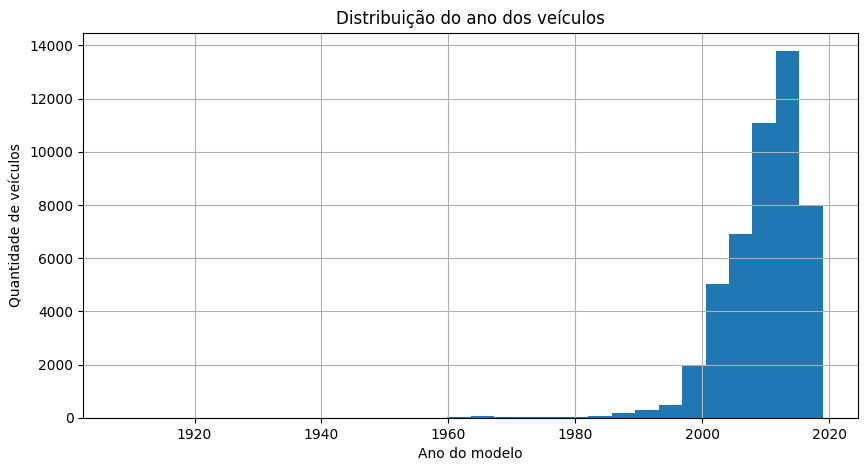

In [54]:
dataframe['model_year'].hist(bins=30, figsize=(10, 5))

plt.title('Distribuição do ano dos veículos')
plt.xlabel('Ano do modelo')
plt.ylabel('Quantidade de veículos')
plt.show()

In [55]:
dataframe.loc[
    dataframe['model_year'].isna(),
    'model'
].value_counts().head(15)

model
ford f-150                    191
chevrolet silverado 1500      155
ram 1500                      117
chevrolet silverado            98
honda accord                   80
ram 2500                       80
jeep wrangler                  70
ford escape                    68
jeep grand cherokee            68
honda civic                    60
toyota tacoma                  58
chevrolet tahoe                54
chevrolet silverado 2500hd     54
gmc sierra 1500                54
toyota camry                   54
Name: count, dtype: int64

In [56]:
dataframe.groupby('model')['model_year'].agg(
    ['count', 'median']
).sort_values('count').head(15)

,count,median
model,,
mercedes-benz benze sprinter 2500,34,2013.0
nissan murano,215,2009.0
ford f-250 super duty,219,2008.0
kia sorento,222,2013.0
dodge dakota,224,2004.0
acura tl,224,2007.0
chrysler 200,224,2014.0
ford f350 super duty,228,2006.5
chevrolet silverado 3500hd,229,2013.0


In [57]:
medianas_por_modelo = dataframe.groupby('model')['model_year'].transform('median')

dataframe['model_year'] = dataframe['model_year'].fillna(
    medianas_por_modelo.round()
)

In [58]:
dataframe['model_year'].isna().sum()

np.int64(0)

In [59]:
dataframe['cylinders'].value_counts().sort_index()

cylinders
3.0        34
4.0     13864
5.0       272
6.0     15700
8.0     15844
10.0      549
12.0        2
Name: count, dtype: int64

In [60]:
dataframe['cylinders'].isna().sum()

np.int64(5260)

In [61]:
dataframe.groupby('model')['cylinders'].agg(
    ['count', 'median']
).sort_values('count').head(15)

,count,median
model,,
mercedes-benz benze sprinter 2500,34,6.0
nissan murano,202,6.0
kia sorento,209,4.0
acura tl,211,6.0
subaru impreza,215,4.0
ford f-250 super duty,216,8.0
chrysler 200,219,4.0
chevrolet silverado 3500hd,221,8.0
ford f350,222,8.0


In [62]:
dataframe.groupby('model')['cylinders'].median().isna().sum()

np.int64(0)

In [63]:
medianas_cilindros = dataframe.groupby('model')['cylinders'].transform('median')

dataframe['cylinders'] = dataframe['cylinders'].fillna(
    medianas_cilindros
)

In [64]:
dataframe['cylinders'].isna().sum()


np.int64(0)

In [65]:
dataframe['odometer'].describe()

count     43633.000000
mean     115553.461738
std       65094.611341
min           0.000000
25%       70000.000000
50%      113000.000000
75%      155000.000000
max      990000.000000
Name: odometer, dtype: float64

In [67]:
dataframe.groupby('model_year')['odometer'].median().head(15)

model_year
1908.0    169328.0
1929.0         NaN
1936.0     30000.0
1948.0      4000.0
1949.0      1800.0
1954.0      3565.0
1955.0     47180.0
1958.0     32991.5
1960.0     16000.0
1961.0     66000.0
1962.0     72000.0
1963.0     40487.0
1964.0     58000.0
1965.0     51330.5
1966.0     63070.0
Name: odometer, dtype: float64

In [68]:
dataframe.groupby(['model', 'model_year'])['odometer'].median().isna().sum()

np.int64(38)

In [69]:
mediana_modelo_ano = dataframe.groupby(
    ['model', 'model_year']
)['odometer'].transform('median')

mediana_modelo = dataframe.groupby(
    'model'
)['odometer'].transform('median')

print('Valores ausentes inicialmente:', dataframe['odometer'].isna().sum())

print('Grupos sem mediana por modelo e ano:', mediana_modelo_ano.isna().sum())

print('Grupos sem mediana por modelo:', mediana_modelo.isna().sum())

Valores ausentes inicialmente: 7892
Grupos sem mediana por modelo e ano: 83
Grupos sem mediana por modelo: 41


In [70]:
dataframe['odometer'] = dataframe['odometer'].fillna(
    mediana_modelo_ano
)

dataframe['odometer'] = dataframe['odometer'].fillna(
    mediana_modelo
)

In [71]:
dataframe['odometer'].isna().sum()

np.int64(41)

In [72]:
mediana_geral = dataframe['odometer'].median()

dataframe['odometer'] = dataframe['odometer'].fillna(
    mediana_geral
)

In [73]:
dataframe['odometer'].isna().sum()

np.int64(0)

In [74]:
dataframe['paint_color'].value_counts()

paint_color
white     10029
black      7692
silver     6244
grey       5037
blue       4475
red        4421
green      1396
brown      1223
custom     1153
yellow      255
orange      231
purple      102
Name: count, dtype: int64

In [75]:
dataframe['paint_color'].isna().sum()

np.int64(9267)

In [76]:
dataframe['paint_color'] = dataframe['paint_color'].fillna('unknown')

In [77]:
dataframe['paint_color'].isna().sum()

np.int64(0)

In [78]:
dataframe['paint_color'].value_counts()

paint_color
white      10029
unknown     9267
black       7692
silver      6244
grey        5037
blue        4475
red         4421
green       1396
brown       1223
custom      1153
yellow       255
orange       231
purple       102
Name: count, dtype: int64

In [79]:
dataframe['is_4wd'].value_counts(dropna=False)

is_4wd
NaN    25953
1.0    25572
Name: count, dtype: int64

In [80]:
dataframe.groupby('model')['is_4wd'].agg(
    ['count', 'sum']
).sort_values('sum', ascending=False).head(15)

,count,sum
model,,
ford f-150,2048,2048.0
chevrolet silverado 1500,1644,1644.0
ram 1500,1229,1229.0
jeep wrangler,1090,1090.0
ram 2500,954,954.0
chevrolet silverado,928,928.0
chevrolet silverado 2500hd,785,785.0
gmc sierra 1500,720,720.0
jeep grand cherokee,707,707.0


In [81]:
dataframe.groupby('model')['is_4wd'].agg(
    total='size',
    informados='count',
    tracao_4wd='sum'
).assign(
    percentual_4wd=lambda x: (
        x['tracao_4wd'] / x['informados'] * 100
    )
).sort_values('percentual_4wd', ascending=False).head(15)

,total,informados,tracao_4wd,percentual_4wd
model,,,,
acura tl,236,19,19.0,100.0
bmw x5,267,243,243.0,100.0
buick enclave,271,128,128.0,100.0
cadillac escalade,322,255,255.0,100.0
chevrolet camaro,414,51,51.0,100.0
chevrolet colorado,286,183,183.0,100.0
chevrolet corvette,499,4,4.0,100.0
chevrolet cruze,457,6,6.0,100.0
chevrolet equinox,591,279,279.0,100.0


In [82]:
dataframe['is_4wd'].isna().sum()

np.int64(25953)

In [83]:
dataframe.isna().sum()

price               0
model_year          0
model               0
condition           0
cylinders           0
fuel                0
odometer            0
transmission        0
type                0
paint_color         0
is_4wd          25953
date_posted         0
days_listed         0
dtype: int64

In [84]:
dataframe.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 51525 entries, 0 to 51524
Data columns (total 13 columns):
 #   Column        Non-Null Count  Dtype         
---  ------        --------------  -----         
 0   price         51525 non-null  int64         
 1   model_year    51525 non-null  float64       
 2   model         51525 non-null  object        
 3   condition     51525 non-null  object        
 4   cylinders     51525 non-null  float64       
 5   fuel          51525 non-null  object        
 6   odometer      51525 non-null  float64       
 7   transmission  51525 non-null  object        
 8   type          51525 non-null  object        
 9   paint_color   51525 non-null  object        
 10  is_4wd        25572 non-null  float64       
 11  date_posted   51525 non-null  datetime64[ns]
 12  days_listed   51525 non-null  int64         
dtypes: datetime64[ns](1), float64(4), int64(2), object(6)
memory usage: 5.1+ MB


In [85]:
dataframe['model_year'] = dataframe['model_year'].astype('int64')

dataframe['cylinders'] = dataframe['cylinders'].astype('int64')

dataframe['odometer'] = dataframe['odometer'].astype('int64')

In [86]:
dataframe.dtypes

price                    int64
model_year               int64
model                   object
condition               object
cylinders                int64
fuel                    object
odometer                 int64
transmission            object
type                    object
paint_color             object
is_4wd                 float64
date_posted     datetime64[ns]
days_listed              int64
dtype: object

In [87]:
dataframe.duplicated().sum()

np.int64(0)

In [88]:
dataframe['price'].describe()

count     51525.000000
mean      12132.464920
std       10040.803015
min           1.000000
25%        5000.000000
50%        9000.000000
75%       16839.000000
max      375000.000000
Name: price, dtype: float64

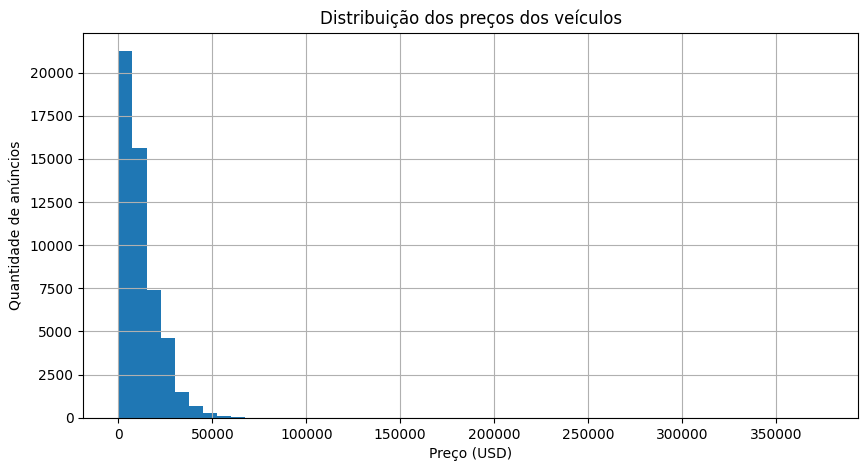

In [89]:
dataframe['price'].hist(bins=50, figsize=(10, 5))

plt.title('Distribuição dos preços dos veículos')
plt.xlabel('Preço (USD)')
plt.ylabel('Quantidade de anúncios')
plt.show()